# 03 — U-Net Evaluation for Whole-Gland Segmentation

## Objective

This notebook evaluates the best U-Net checkpoint obtained during
training for prostate whole-gland segmentation.

The workflow includes:

1. Environment and path configuration
2. Loading validation and test datasets
3. Loading the best U-Net checkpoint
4. Quantitative evaluation using loss, Dice, positive-slice Dice, and IoU
5. Qualitative visualization of segmentation predictions
6. Saving the final segmentation metrics

The test set is used only for final evaluation and is not used for
model selection or hyperparameter tuning.

## 1. Environment Setup

The project root is added to the Python path so that the evaluation
notebook can import the reusable modules implemented in the `src`
package.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II


## 2. Imports and Evaluation Paths

This section imports the PyTorch components and project modules required
to load the validation and test datasets, restore the best U-Net
checkpoint, compute segmentation metrics, and visualize predictions.

In [2]:
import pandas as pd
import torch
import importlib

from torch.utils.data import DataLoader

In [3]:
import src.data.paths
importlib.reload(src.data.paths)

import src.segmentation.dataset
importlib.reload(src.segmentation.dataset)

import src.segmentation.model
importlib.reload(src.segmentation.model)

import src.segmentation.losses
importlib.reload(src.segmentation.losses)

import src.segmentation.train
importlib.reload(src.segmentation.train)

import src.visualization.visualization
importlib.reload(src.visualization.visualization)

<module 'src.visualization.visualization' from 'c:\\Users\\Luiz Trindade\\Documents\\penguin-adventure\\TCC_II\\src\\visualization\\visualization.py'>

In [4]:
from src.data.paths import (
    PROCESSED_DIR,
    SPLITS_DIR,
    CHECKPOINTS_DIR,
)

from src.segmentation.dataset import (
    ProstateSegmentationDataset,
)

from src.segmentation.model import (
    UNet,
)

from src.segmentation.losses import (
    BCEDiceLoss,
)

from src.segmentation.train import (
    evaluate_model,
)

from src.visualization.visualization import (
    plot_segmentation_prediction,
)

In [5]:
processed_dataset_dir = (
    PROCESSED_DIR
    / "whole_gland_2d"
)

images_dir = (
    processed_dataset_dir
    / "images"
)

masks_dir = (
    processed_dataset_dir
    / "masks"
)

splits_csv = (
    SPLITS_DIR
    / "patient_splits.csv"
)

checkpoint_path = (
    CHECKPOINTS_DIR
    / "unet_whole_gland_best.pth"
)

print("Images:", images_dir)
print("Masks:", masks_dir)
print("Splits:", splits_csv)
print("Checkpoint:", checkpoint_path)

Images: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\whole_gland_2d\images
Masks: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\whole_gland_2d\masks
Splits: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\splits\patient_splits.csv
Checkpoint: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\checkpoints\unet_whole_gland_best.pth


## 3. Evaluation Datasets

The validation and test subsets are loaded using the same patient-level
partition defined during data preparation.

The validation subset is used to report performance on the data used
during model selection, while the test subset provides the final
evaluation on unseen cases.

No data shuffling is applied during evaluation.

In [6]:
validation_dataset = ProstateSegmentationDataset(
    images_dir=images_dir,
    masks_dir=masks_dir,
    splits_csv=splits_csv,
    split="validation",
)

test_dataset = ProstateSegmentationDataset(
    images_dir=images_dir,
    masks_dir=masks_dir,
    splits_csv=splits_csv,
    split="test",
)

print(
    "Validation slices:",
    len(validation_dataset),
)

print(
    "Test slices:",
    len(test_dataset),
)

Validation slices: 4246
Test slices: 4313


In [7]:
validation_loader = DataLoader(
    validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

print(
    "Validation batches:",
    len(validation_loader),
)

print(
    "Test batches:",
    len(test_loader),
)

Validation batches: 531
Test batches: 540


## 4. Best Model Checkpoint

The U-Net architecture is initialized and the best checkpoint obtained
during training is loaded.

The checkpoint corresponds to the epoch with the lowest validation loss
and is used for all subsequent quantitative and qualitative evaluation.

In [8]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = UNet(
    in_channels=1,
    out_channels=1,
).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Device:", device)
print(
    "Checkpoint epoch:",
    checkpoint["epoch"],
)
print(
    "Validation loss:",
    checkpoint["validation_loss"],
)

Device: cuda
Checkpoint epoch: 4
Validation loss: 0.09499987257248152


## 5. Validation Set Evaluation

The best U-Net checkpoint is first evaluated on the validation subset.

Performance is reported using the combined segmentation loss, Dice
coefficient, Dice coefficient restricted to slices containing prostate
tissue, and Intersection over Union (IoU).

In [10]:
criterion = BCEDiceLoss()

validation_metrics = evaluate_model(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print(
    "Validation loss:",
    validation_metrics["loss"],
)

print(
    "Validation Dice:",
    validation_metrics["dice"],
)

print(
    "Validation positive-slice Dice:",
    validation_metrics["positive_dice"],
)

print(
    "Validation IoU:",
    validation_metrics["iou"],
)

Validation loss: 0.09499987257248152
Validation Dice: 0.8384125903389099
Validation positive-slice Dice: 0.8158328438354874
Validation IoU: 0.7942815749097454


## 6. Test Set Evaluation

After model selection was completed using the validation subset, the
best checkpoint is evaluated on the independent test subset.

The test set is used only for final performance estimation and does not
influence training or checkpoint selection.

In [11]:
test_metrics = evaluate_model(
    model=model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
)

print(
    "Test loss:",
    test_metrics["loss"],
)

print(
    "Test Dice:",
    test_metrics["dice"],
)

print(
    "Test positive-slice Dice:",
    test_metrics["positive_dice"],
)

print(
    "Test IoU:",
    test_metrics["iou"],
)

Test loss: 0.1010370206648346
Test Dice: 0.8317748599582249
Test positive-slice Dice: 0.8145520106496875
Test IoU: 0.7868467372738652


## 7. Quantitative Evaluation Summary

The best U-Net checkpoint achieved similar performance on the validation
and test subsets.

On the validation set, the model obtained:

- Loss: 0.0950
- Dice coefficient: 0.8384
- Positive-slice Dice coefficient: 0.8158
- IoU: 0.7943

On the independent test set, the model obtained:

- Loss: 0.1010
- Dice coefficient: 0.8318
- Positive-slice Dice coefficient: 0.8146
- IoU: 0.7868

The small difference between validation and test performance indicates
that the selected checkpoint generalizes consistently to unseen cases.

The positive-slice Dice coefficient is particularly relevant because it
evaluates segmentation performance only on slices containing prostate
tissue, reducing the influence of empty background slices.

## 8. Qualitative Segmentation Analysis

To complement the quantitative metrics, selected test samples are
visualized together with the ground-truth mask and the segmentation
predicted by the U-Net.

This qualitative analysis helps assess whether the predicted prostate
boundaries are spatially consistent with the reference annotations.

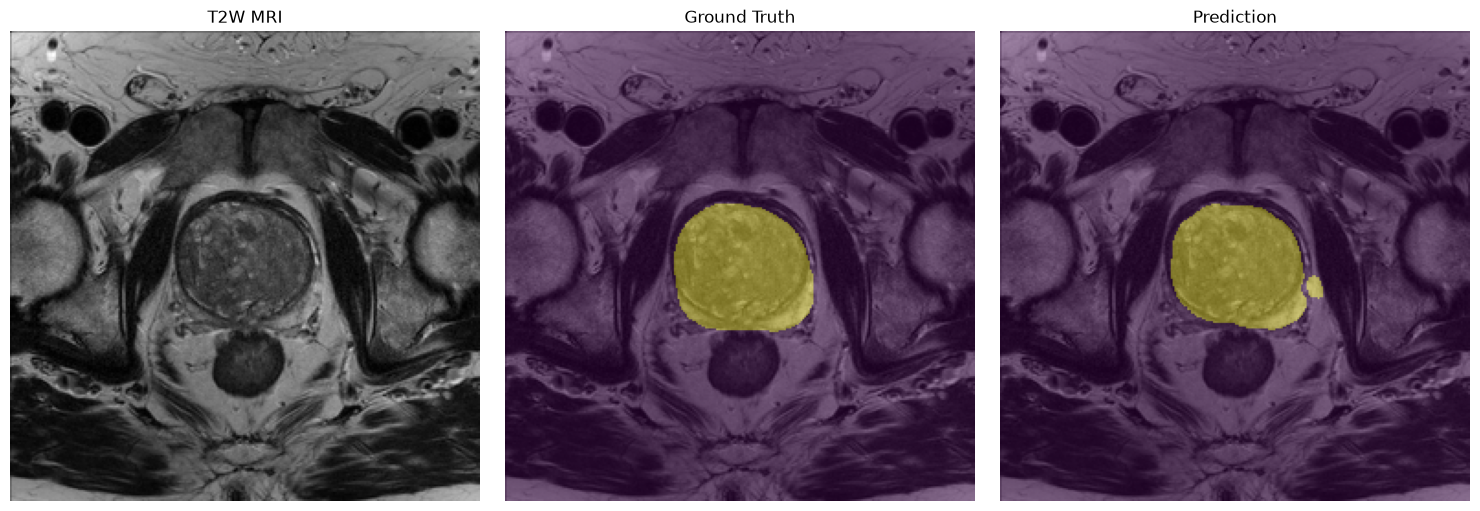

In [16]:
largest_image_batch = (
    largest_image
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():
    largest_logits = model(
        largest_image_batch
    )

plot_segmentation_prediction(
    image=largest_image,
    mask=largest_mask,
    logits=largest_logits[0].cpu(),
    threshold=0.5,
)

In [17]:
from src.segmentation.metrics import (
    dice_score,
    iou_score,
)

slice_dice = dice_score(
    largest_logits,
    largest_mask
    .unsqueeze(0)
    .to(device),
)

slice_iou = iou_score(
    largest_logits,
    largest_mask
    .unsqueeze(0)
    .to(device),
)

print(
    "Slice Dice:",
    slice_dice,
)

print(
    "Slice IoU:",
    slice_iou,
)

Slice Dice: 0.9503538012504578
Slice IoU: 0.905414342880249


### 8.1 Qualitative Example

For the selected test slice (`10001_1000001_slice_008.npy`), the
predicted prostate region closely matches the reference segmentation.

The slice achieved:

- Dice coefficient: 0.9504
- IoU: 0.9054

A small isolated false-positive region is visible adjacent to the main
prostate segmentation. Despite this error, the overall gland contour
shows strong spatial agreement with the ground-truth annotation.

This example illustrates that the U-Net is capable of accurately
segmenting the prostate on representative axial T2W MRI slices while
still presenting localized segmentation errors.

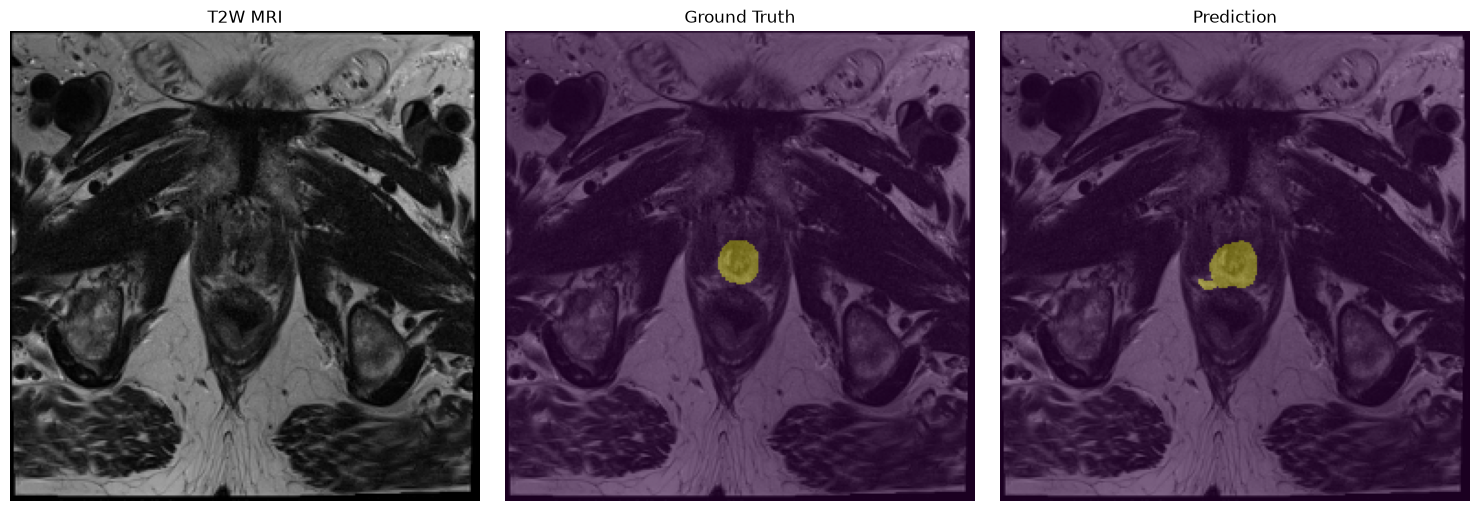

In [20]:
plot_segmentation_prediction(
    image=representative_image,
    mask=representative_mask,
    logits=representative_logits[0],
    threshold=0.5,
)

### 8.2 Representative Test Example

A second test sample was selected based on its Dice coefficient being
closest to the mean positive-slice Dice observed across the test set.

For `10815_1000831_slice_004.npy`, the model achieved:

- Dice coefficient: 0.8146
- IoU: 0.6875

The predicted segmentation correctly identifies the prostate region,
although differences are visible along the gland boundary.

Compared with the previous high-performing example, this sample provides
a more representative visualization of the model's average segmentation
performance on positive test slices.

Together, these examples illustrate both strong and typical segmentation
behavior of the trained U-Net.

## 9. Saving Evaluation Results

The final validation and test metrics are stored in a CSV file to ensure
that the segmentation results can be reused in subsequent analyses and
reported consistently throughout the project.

In [21]:
evaluation_results = pd.DataFrame(
    [
        {
            "split": "validation",
            "loss": validation_metrics["loss"],
            "dice": validation_metrics["dice"],
            "positive_dice": validation_metrics["positive_dice"],
            "iou": validation_metrics["iou"],
        },
        {
            "split": "test",
            "loss": test_metrics["loss"],
            "dice": test_metrics["dice"],
            "positive_dice": test_metrics["positive_dice"],
            "iou": test_metrics["iou"],
        },
    ]
)

evaluation_results

,split,loss,dice,positive_dice,iou
0,validation,0.095000,0.838413,0.815833,0.794282
1,test,0.101037,0.831775,0.814552,0.786847


In [22]:
results_dir = (
    PROJECT_ROOT
    / "results"
    / "segmentation"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_path = (
    results_dir
    / "unet_whole_gland_metrics.csv"
)

evaluation_results.to_csv(
    metrics_path,
    index=False,
)

print(
    "Metrics saved to:",
    metrics_path,
)

Metrics saved to: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\segmentation\unet_whole_gland_metrics.csv


In [23]:
saved_metrics = pd.read_csv(
    metrics_path
)

saved_metrics

,split,loss,dice,positive_dice,iou
0,validation,0.095000,0.838413,0.815833,0.794282
1,test,0.101037,0.831775,0.814552,0.786847


## 10. Segmentation Evaluation Summary

The best U-Net checkpoint was evaluated on both the validation and
independent test subsets of the PI-CAI dataset.

On the test subset, the model achieved:

- Loss: 0.1010
- Dice coefficient: 0.8318
- Positive-slice Dice coefficient: 0.8146
- IoU: 0.7868

The similarity between validation and test performance indicates
consistent segmentation behavior on unseen cases.

Qualitative inspection also showed that the model is capable of
correctly localizing the prostate and producing segmentation boundaries
that generally agree with the reference whole-gland annotations,
although localized false-positive and boundary errors remain present.

The final quantitative results were saved to
`results/segmentation/unet_whole_gland_metrics.csv` for reproducible
reuse in subsequent stages of the project.

The evaluated U-Net checkpoint is therefore retained as the segmentation
model for the next stage of the pipeline.